# Giai đoạn 1–3: Gộp dữ liệu thô & Chuẩn hóa 22 nhãn (EDA)

Quy trình thực hiện trong notebook này trên dữ liệu `webtruyen.vn` (`wetruyen.com`):
1. Đọc tệp dữ liệu crawl gốc `data/raw/webtruyen_raw.csv` (**`55.684` bản ghi thô**, cào đủ **42 chuyên mục thể loại × toàn bộ các trang**).
2. Áp dụng `deduplicate_stories()` (loại trùng tên `title` và trùng `summary` kèm gộp thẻ `genres_raw` $\rightarrow$ **`18.621` truyện duy nhất**, loại `37.063` bản ghi trùng giữa các thẻ) và bỏ `18` mẫu chỉ mang các thẻ loại (`khác`, `đoản văn`, `tiểu thuyết`, `phương tây`, `quan trường`, `việt nam`), thu được **`18.603` truyện hợp lệ (`99.90%`)**.
3. Ánh xạ lại 42 thẻ gốc sang **22 nhãn chuẩn**, xuất cột `genres`, `n_labels`, `n_words` và 22 cột one-hot vào **`data/processed/stories.csv`** (`18.603` dòng × `36` cột).
4. Thực hiện EDA đa nhãn: `label cardinality = 2.6704`, `label density = 0.1214`, độ dài `summary` (`min=15`, `mean=202.76`, `median=157`, `max=3.598`), ma trận đồng xuất hiện `22×22` và biểu đồ `outputs/figures/eda_overview.png`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from src.config import (
    ACTIVE_RAW_CSV,
    FIGURES_DIR,
    GENRE_DISPLAY_NAMES,
    GENRE_LABELS,
    MIN_SUMMARY_WORDS,
    STORIES_CSV,
)
from src.crawl.merge_data import REQUIRED_RAW_COLUMNS, deduplicate_stories, normalize_genres

raw_files = [ACTIVE_RAW_CSV]
frames = []
for csv_path in raw_files:
    part_df = pd.read_csv(csv_path, encoding="utf-8")
    print(f"Đọc {csv_path.name:22s}: {len(part_df):5d} bản ghi")
    frames.append(part_df)

df_raw = pd.concat(frames, ignore_index=True)
print(f"\nTổng số bản ghi thô trước khi lọc: {len(df_raw)}")
df_raw[["id", "title", "genres_raw", "source"]].head()

Đọc webtruyen_raw.csv     : 55684 bản ghi

Tổng số bản ghi thô trước khi lọc: 55684


,id,title,genres_raw,source
0,WT_0001,Con Đường Bá Chủ,Tiên Hiệp|Cổ Đại|Huyền Huyễn,webtruyen.vn
1,WT_0002,Mục Thần Ký,Tiên Hiệp|Huyền Huyễn,webtruyen.vn
2,WT_0003,Vô Thượng Sát Thần,Tiên Hiệp|Xuyên Không,webtruyen.vn
3,WT_0004,Thần Đạo Đan Tôn,Tiên Hiệp|Huyền Huyễn|Trọng Sinh,webtruyen.vn
4,WT_0005,Tiên Nghịch,Tiên Hiệp|Kiếm Hiệp|Huyền Huyễn,webtruyen.vn


In [2]:
# Chuẩn hóa các cột bắt buộc, loại trùng lặp tên truyện/summary và lọc bài quá ngắn
df_merged = df_raw.copy()
for col in REQUIRED_RAW_COLUMNS:
    if col not in df_merged.columns:
        df_merged[col] = ""

n_before = len(df_merged)
df_merged = deduplicate_stories(df_merged)
n_after_dedup = len(df_merged)

df_merged["n_words"] = df_merged["summary"].apply(lambda text: len(text.split()))
df_merged = df_merged[df_merged["n_words"] >= MIN_SUMMARY_WORDS].reset_index(drop=True)

print(f"Trước khi lọc        : {n_before}")
print(f"Sau khi bỏ rỗng/trùng: {n_after_dedup} (loại {n_before - n_after_dedup})")
print(f"Sau lọc >= {MIN_SUMMARY_WORDS} từ     : {len(df_merged)}")

Trước khi lọc        : 55684
Sau khi bỏ rỗng/trùng: 18621 (loại 37063)
Sau lọc >= 10 từ     : 18621


In [3]:
# Chuẩn hóa sang 22 nhãn chuẩn vào stories.csv
from src.crawl.merge_data import merge_raw_and_labeled
from src.config import ACTIVE_RAW_CSV

df_stories = merge_raw_and_labeled(input_csvs=(ACTIVE_RAW_CSV,))
print(f"Đã xuất {len(df_stories)} truyện ({len(GENRE_LABELS)} nhãn chuẩn) vào: {STORIES_CSV}")
df_stories[["id", "title", "genres", "n_labels", "n_words"]].head()

Đã xuất 18603 truyện (22 nhãn chuẩn) vào: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\data\processed\stories.csv


,id,title,genres,n_labels,n_words
0,ST_0001,Con Đường Bá Chủ,tien_hiep|co_dai|huyen_huyen,3,469
1,ST_0002,Mục Thần Ký,tien_hiep|huyen_huyen,2,120
2,ST_0003,Vô Thượng Sát Thần,tien_hiep|xuyen_khong,2,100
3,ST_0004,Thần Đạo Đan Tôn,tien_hiep|huyen_huyen|trong_sinh,3,308
4,ST_0005,Tiên Nghịch,tien_hiep|kiem_hiep|huyen_huyen,3,139


In [4]:
# Thống kê EDA đa nhãn trên stories.csv vừa xuất
label_cols = [f"label_{g}" for g in GENRE_LABELS]
cardinality = df_stories["n_labels"].mean()
density = cardinality / len(GENRE_LABELS)

print(f"Tổng số mẫu: {len(df_stories)} | Số nhãn: {len(GENRE_LABELS)}")
print(f"Label cardinality: {cardinality:.4f} | Label density: {density:.4f}")
print(
    f"Độ dài summary (từ): min={df_stories['n_words'].min()}, "
    f"mean={df_stories['n_words'].mean():.2f}, "
    f"median={df_stories['n_words'].median():.0f}, "
    f"max={df_stories['n_words'].max()}"
)

print("\n--- Phân bố theo nguồn ---")
print(df_stories["source"].value_counts())

summary_rows = []
for g in GENRE_LABELS:
    sub = df_stories[df_stories[f"label_{g}"] == 1]
    summary_rows.append(
        {
            "label": g,
            "ten_hien_thi": GENRE_DISPLAY_NAMES.get(g, g),
            "so_mau": len(sub),
            "ty_le_%": round(len(sub) / len(df_stories) * 100, 2),
            "do_dai_tb_tu": round(sub["n_words"].mean(), 1) if len(sub) else 0.0,
        }
    )
eda_genre_df = pd.DataFrame(summary_rows).sort_values("so_mau", ascending=False).reset_index(drop=True)
eda_genre_df

Tổng số mẫu: 18603 | Số nhãn: 22
Label cardinality: 2.6704 | Label density: 0.1214
Độ dài summary (từ): min=15, mean=202.76, median=157, max=3598

--- Phân bố theo nguồn ---
source
webtruyen.vn    18603
Name: count, dtype: int64


,label,ten_hien_thi,so_mau,ty_le_%,do_dai_tb_tu
0,ngon_tinh,Ngôn tình (Nam–Nữ),8702,46.78,208.0
1,co_dai,Cổ đại,5833,31.36,186.2
2,hien_dai,Hiện đại / Đô thị,5613,30.17,213.0
3,sung,Sủng / Ngọt,4568,24.56,244.0
4,dam_my,Đam mỹ,3921,21.08,248.0
5,nu_cuong,Nữ cường,3524,18.94,163.8
6,xuyen_khong,Xuyên không / Xuyên nhanh,2299,12.36,242.1
7,trong_sinh,Trọng sinh,2135,11.48,210.3
8,hai_huoc,Hài hước,1979,10.64,198.1
9,huyen_huyen,Huyền huyễn / Dị giới,1891,10.17,200.8


Ma trận đồng xuất hiện giữa các thể loại:


,ngon_tinh,dam_my,bach_hop,tien_hiep,kiem_hiep,huyen_huyen,linh_di,khoa_huyen_mat_the,vong_du,trinh_tham,...,co_dai,hien_dai,cung_dau_gia_dau,xuyen_khong,trong_sinh,he_thong,nu_cuong,sung,nguoc,hai_huoc
ngon_tinh,8702,73,15,162,26,477,160,206,26,85,...,2867,3037,889,1063,922,307,1737,3055,1031,1175
dam_my,73,3921,1,142,35,361,202,196,48,59,...,658,1096,102,603,396,213,1,1183,362,396
bach_hop,15,1,416,11,0,14,10,9,3,3,...,84,151,20,59,45,11,16,80,30,34
tien_hiep,162,142,11,1217,87,514,32,34,4,3,...,342,36,15,222,100,65,116,119,30,129
kiem_hiep,26,35,0,87,320,67,3,1,3,7,...,64,5,6,42,6,5,3,5,7,4
huyen_huyen,477,361,14,514,67,1891,212,143,16,25,...,559,226,74,387,165,129,232,250,77,232
linh_di,160,202,10,32,3,212,619,72,1,53,...,110,245,25,56,30,26,94,110,25,81
khoa_huyen_mat_the,206,196,9,34,1,143,72,728,26,16,...,109,223,30,188,94,108,132,150,21,93
vong_du,26,48,3,4,3,16,1,26,148,0,...,5,26,2,17,7,14,7,21,0,12
trinh_tham,85,59,3,3,7,25,53,16,0,233,...,44,75,3,15,7,6,28,36,13,15


Đã lưu biểu đồ tại: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\eda_overview.png


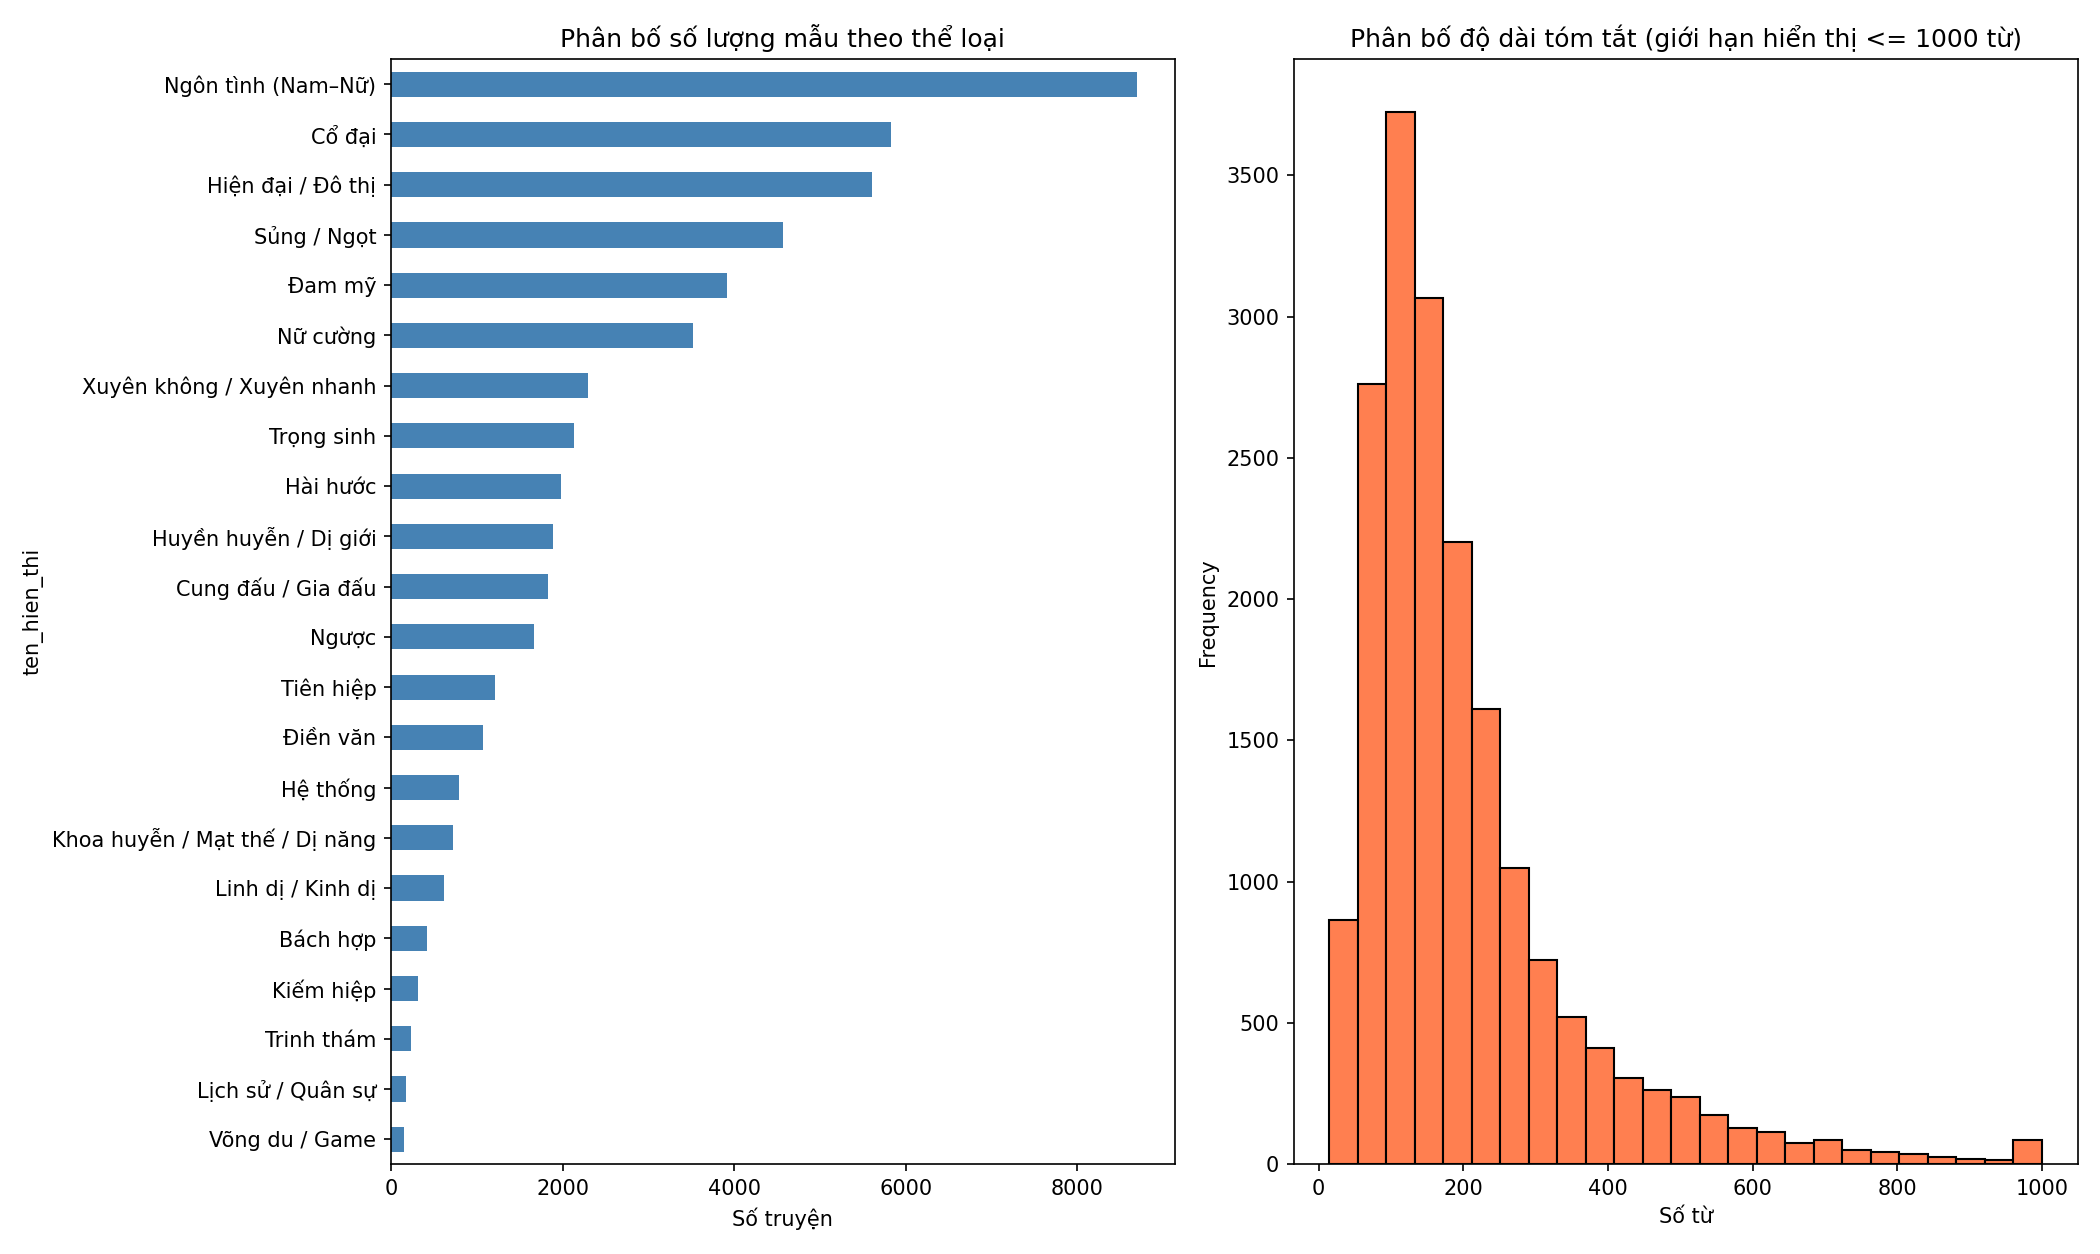

In [5]:
# Ma trận đồng xuất hiện nhãn và vẽ biểu đồ EDA (nếu đã cài matplotlib)
co_occurrence = df_stories[label_cols].T @ df_stories[label_cols]
co_occurrence.index = GENRE_LABELS
co_occurrence.columns = GENRE_LABELS
print("Ma trận đồng xuất hiện giữa các thể loại:")
display(co_occurrence)

try:
    import matplotlib.pyplot as plt

    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, max(5, 0.38 * len(GENRE_LABELS))))

    eda_genre_df.set_index("ten_hien_thi")["so_mau"].sort_values().plot(
        kind="barh", ax=axes[0], color="steelblue"
    )
    axes[0].set_title("Phân bố số lượng mẫu theo thể loại")
    axes[0].set_xlabel("Số truyện")

    df_stories["n_words"].clip(upper=1000).plot(
        kind="hist", bins=25, ax=axes[1], color="coral", edgecolor="black"
    )
    axes[1].set_title("Phân bố độ dài tóm tắt (giới hạn hiển thị <= 1000 từ)")
    axes[1].set_xlabel("Số từ")

    plt.tight_layout()
    out_fig = FIGURES_DIR / "eda_overview.png"
    plt.savefig(out_fig, dpi=150)
    plt.close(fig)
    from IPython.display import Image, display
    print(f"Đã lưu biểu đồ tại: {out_fig}")
    display(Image(filename=str(out_fig)))
except ImportError:
    print("Lưu ý: Chưa cài matplotlib nên bỏ qua bước xuất biểu đồ PNG (cài bằng pip install -r requirements.txt).")

## Tổng kết Giai đoạn 1–3 (Thu thập, Chuẩn hóa 22 nhãn & EDA)

- **Quy mô dữ liệu (`webtruyen.vn`):** Thu thập **`55.684` bản ghi thô** từ `42` chuyên mục (`2.269` trang) → khử trùng tên truyện & văn án thu được **`18.621` truyện duy nhất** → loại `18` truyện chỉ chứa thẻ rác trong `NON_GENRE_TAGS` (`Khác`, `Đoản Văn`, `Tiểu Thuyết`, `Phương Tây`, `Quan Trường`, `Việt Nam`), giữ lại **`18.603` truyện hợp lệ (`99.90%`)** trên **22 nhãn chuẩn** (`data/processed/stories.csv`).
- **Đặc trưng bài toán đa nhãn:** `Label cardinality = 2.6704` nhãn/truyện, `Label density = 0.1214`, mỗi truyện có từ `1` đến `11` nhãn; độ dài `summary` dao động `15`–`3.598` từ (trung bình `202.76` từ, trung vị `157` từ).
- **Mất cân bằng lớp (`58.8 : 1`):** Nhãn phổ biến nhất là `ngon_tinh` (`8.702`), `co_dai` (`5.833`), `hien_dai` (`5.613`), `sung` (`4.568`), `dam_my` (`3.921`); nhãn ít mẫu nhất là `vong_du` (`148`), `lich_su_quan_su` (`176`), `trinh_tham` (`233`), `kiem_hiep` (`320`), `bach_hop` (`416`) → là cơ sở áp dụng `IterativeStratification` khi chia tập, `class_weight="balanced"`, `sqrt pos_weight` và tối ưu ngưỡng quyết định theo từng nhãn ở các giai đoạn sau.
- **Cặp nhãn đồng xuất hiện mạnh nhất (`22×22`):** `ngon_tinh & sung` (`3.055`), `ngon_tinh & hien_dai` (`3.037`), `ngon_tinh & co_dai` (`2.867`), `co_dai & nu_cuong` (`2.167`), `co_dai & cung_dau_gia_dau` (`1.543`). Biểu đồ tổng quan lưu tại `outputs/figures/eda_overview.png`.